**Kotsonas Kyriakos Exercise 4**

k-Means = 20 and using PCA, 5000 samples


In [1]:
# Install the Rapid Deep Neural Networks library
!pip install radnn -q
!pip list | grep "radnn"

from radnn.system.hosts import ColabHost

# Mount to the project folder that is under the lesson folder
ColabHost().detect_workspace(["CS345", "MSDS680"]).change_to_project_dir("Exercise 44")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 1.4 MB/s eta 0:00:00
radnn                              0.0.8
Mounted at /content/gdrive
Current directory is:  /content/gdrive/My Drive/Colab Notebooks/MSDS680/Exercise 44


Host: (colab)-172.28.0.12

In [2]:
from radnn import FileSystem, FileStore

oFileSys = FileSystem(config_folder="MLConfig", model_folder="MLModels", dataset_folder="MLData")

In [3]:
import numpy as np
import tensorflow as tf
from tensorflow import keras

# _____// Data Hyperparameters \\_____

SAMPLE_COUNT = 5000  # How many samples to use from the available population in the dataset

(train_images, train_labels), (test_images, test_labels) = keras.datasets.fashion_mnist.load_data()
sDataName = "Fashion MNIST"  # Corrected dataset name
nSamples = train_images[:SAMPLE_COUNT]  # Corrected variable name
nLabels = train_labels[:SAMPLE_COUNT]  # Corrected variable name

n_samples, height, width = nSamples.shape
nSamples_reshaped = nSamples.reshape((n_samples, height * width))

print("Loaded %s dataset" % sDataName)
print("Training set shape:", nSamples.shape)
print("Class count:", len(np.unique(nLabels)))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Loaded Fashion MNIST dataset
Training set shape: (5000, 28, 28)
Class count: 10


# Data Preprocessing.

In [4]:
from sklearn.preprocessing import StandardScaler

print("First sample in dataset, features 40-100, before standardization")

# Standardization
nSampleIndex = 0
nFromFeature = 140
nToFeature = 160

oScaler = StandardScaler()
nStandardizedSamples = oScaler.fit_transform(nSamples_reshaped)

print("Sample#1 original features %d-%d" % (nFromFeature, nToFeature))
print(nSamples[nSampleIndex,nFromFeature:nToFeature])
print("Mean μ of features %d-%d over %d samples" % (nFromFeature, nToFeature, SAMPLE_COUNT))
print(oScaler.mean_[nFromFeature:nToFeature])
print("Std σ of features %d-%d over %d samples" % (nFromFeature, nToFeature, SAMPLE_COUNT))
print(oScaler.scale_[nFromFeature:nToFeature])
print("Sample#1 standardized features %d-%d" % (nFromFeature, nToFeature))
print(nStandardizedSamples[nSampleIndex,nFromFeature:nToFeature])

First sample in dataset, features 40-100, before standardization
Sample#1 original features 140-160
[]
Mean μ of features 140-160 over 5000 samples
[  0.2866   1.1392   2.3544   5.5196  16.572   36.6176  53.9998  64.695
  76.233   93.3926 102.7766 103.486  104.7628 107.1914 110.374  112.079
 113.6018 114.6092 112.5464 100.6196]
Std σ of features 140-160 over 5000 samples
[ 4.85490066 13.10003906 18.86219501 28.00617817 48.42242059 69.90348325
 82.39285285 86.34816255 89.07948311 91.25292798 93.22455413 91.20418304
 91.69246499 92.71844243 92.75034083 91.53763357 89.53419256 88.91488332
 90.17463417 89.58794392]
Sample#1 standardized features 140-160
[-0.05903313 -0.08696157 -0.1248211  -0.19708508 -0.34223816 -0.52383084
 -0.65539423 -0.74923424 -0.85578629 -1.02344771 -1.10246277 -1.13466287
 -1.07710923 -1.15609578 -0.09028538  1.00418807  0.69692034  0.21808272
  0.34880763  0.24981486]


# Dimensionality Reduction.
with PCA

In [5]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# _____// Dimensionality Reduction Hyperparameters \\_____
COMPONENTS = 2
IS_LINEAR_DIM_REDUCTION = True

# ... Dimensionality Reduction Hyperparameters ...
PERPLEXITY      = 100.0
LEARNING_RATE   = 1000.0
EPOCHS          = 1000
GRADIENT_CALCULATION_ALGORITHM = "barnes_hut" #Fast

if IS_LINEAR_DIM_REDUCTION:
  sDimReductionMethod = "PCA"
  nReducedSamples  = PCA(n_components=COMPONENTS).fit_transform(nStandardizedSamples)
else:
  sDimReductionMethod = "t-SNE"
  oTSNE = TSNE( n_components=COMPONENTS
                ,perplexity=PERPLEXITY, n_iter=EPOCHS
                ,method=GRADIENT_CALCULATION_ALGORITHM
                ,verbose=2
                )
  nReducedSamples  = oTSNE.fit_transform(nStandardizedSamples)

# Visualization of Known Classes
We visualize the samples as points in the 2D space using a different color for each class.

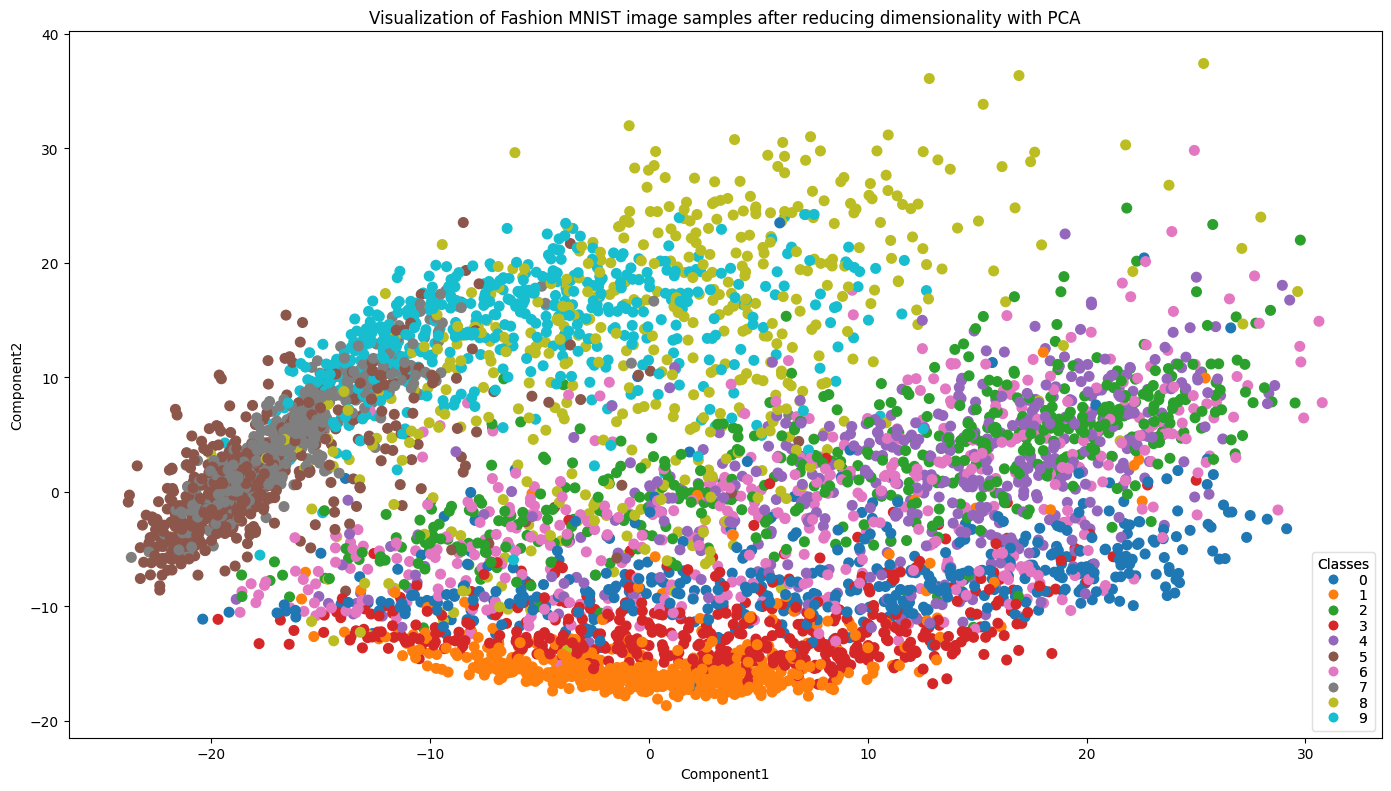

In [6]:
from radnn.plots import MultiScatterPlot

sPlotFileName = oFileSys.models.file(f"{sDataName}_2D_visualization_with_{sDimReductionMethod}.png")

oMultiPlot = MultiScatterPlot(f"Visualization of {sDataName} image samples after reducing dimensionality with {sDimReductionMethod}")
oMultiPlot.add_data("", nReducedSamples, nLabels)
oMultiPlot.prepare(0, "Component1", "Component2").save(sPlotFileName).show()
#oMultiPlot.save(sPlotFileName).show()

#from mllib.visualization import CMultiScatterPlot

#oPlot = CMultiScatterPlot("Visualization of %s image samples after reducing dimensionality with %s" % (sDataName, sDimReductionMethod))
#oPlot.AddData("",nReducedSamples , nLabels)
#oPlot.Show(0, "Component1", "Component2")

# Training
Learn a k-Means clustering model.
with 20 clusters


In [7]:
from sklearn.cluster import KMeans

# _____// Clustering Hyperparameters \\_____
NUM_RUNS_RANDOM_CENTROIDS = 4
RANDOM_SEED               = 2021
#CLUSTER_COUNT_K           = 10
CLUSTER_COUNT_K           = 20
#CLUSTER_COUNT_K           = 50

nReducedSamples = nReducedSamples.astype(np.float64)
oClusteringModel = KMeans(init="k-means++", n_clusters=CLUSTER_COUNT_K, n_init=NUM_RUNS_RANDOM_CENTROIDS, verbose=2)
oClusteringModel.fit(nReducedSamples)

Initialization complete
Iteration 0, inertia 75648.53073147821.
Iteration 1, inertia 65839.39294689056.
Iteration 2, inertia 63856.51192402042.
Iteration 3, inertia 63071.03750861026.
Iteration 4, inertia 62662.07659755978.
Iteration 5, inertia 62329.95671808412.
Iteration 6, inertia 62116.09556290252.
Iteration 7, inertia 62008.53434538691.
Iteration 8, inertia 61871.951436358155.
Iteration 9, inertia 61699.54413330262.
Iteration 10, inertia 61595.06145413185.
Iteration 11, inertia 61521.02589931101.
Iteration 12, inertia 61474.63630460294.
Iteration 13, inertia 61405.44501833311.
Iteration 14, inertia 61329.030496112966.
Iteration 15, inertia 61289.847063048925.
Iteration 16, inertia 61278.37159169148.
Iteration 17, inertia 61271.11479119135.
Iteration 18, inertia 61261.241213126465.
Iteration 19, inertia 61254.00617810346.
Iteration 20, inertia 61244.95682247103.
Iteration 21, inertia 61237.26959336494.
Converged at iteration 21: center shift 0.01355023123687982 within tolerance 0.0

KMeans(n_clusters=20, n_init=4, verbose=2)

# Visualization of Clusters
Visualize the cluster centroids and partitioning of the 2D representation space of an image (after dimensionality reduction) using a Voronoi diagram.

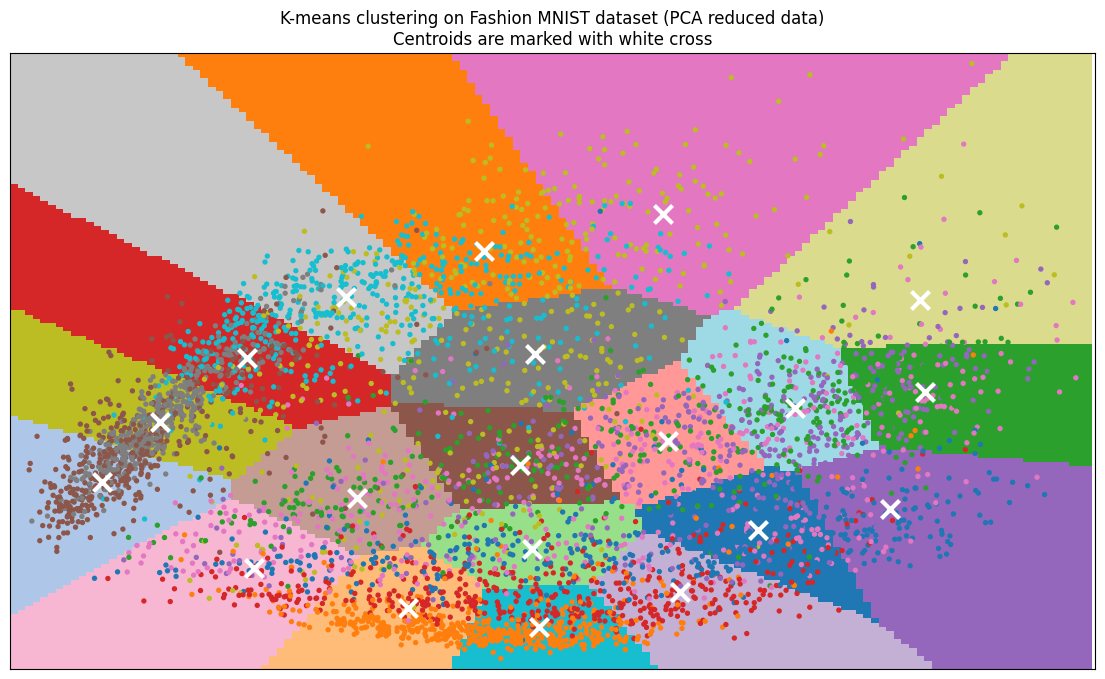

In [8]:
from radnn.plots import PlotVoronoi2D

sPlotFileName = oFileSys.models.file(f"{sDataName}_{CLUSTER_COUNT_K}_clusters.png")

oVoronoi = PlotVoronoi2D(nReducedSamples, nLabels, ground_truth_cluster_count=10,
                         title=f"K-means clustering on {sDataName} "
                         + f"dataset ({sDimReductionMethod} reduced data)\n"
                         + f"Centroids are marked with white cross")
oVoronoi.prepare_for_kmeans(oClusteringModel)
oVoronoi.save(sPlotFileName).show()